# 1 . SVM pour le dataset **iris**

## SVM Noyau Lineaire

In [509]:
import numpy as np
from sklearn.svm import SVC
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score , classification_report
import matplotlib.pyplot as plt


### Chargement et standarisation du data : iris

In [510]:
scaler = StandardScaler()
iris = datasets.load_iris()
X = iris.data
X = scaler.fit_transform(X)
y = iris.target
X = X[y!=0,:2]
y = y[y!= 0]

### Division de l'ensemble de données

On divise l'ensombe de données en deux ensembles
* **Ensemble d'entrainemant** (50%)
* **Ensemble de test** (50%)

In [511]:
X_train , X_test , y_train, y_test = train_test_split(
    X,y,test_size = 0.5 , random_state=42 , stratify=y
)

### Créer et entrainer

In [512]:
# SVM lineaire
clf = SVC(C=0.7,kernel="linear")
clf.fit(X_train,y_train)

SVC(C=0.7, kernel='linear')

### Prédictions

In [513]:
y_pred = clf.predict(X_test)
y_pred

array([2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 1, 1, 1, 2, 2, 1, 2,
       2, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 2, 1, 2, 1, 1, 1, 2, 1, 1,
       2, 2, 2, 2, 2, 1])

### Evaluation

In [514]:
print("Accuracy:",accuracy_score(y_test,y_pred))
print("\nRapport de classification\n",classification_report(y_test,y_pred))

Accuracy: 0.74

Rapport de classification
               precision    recall  f1-score   support

           1       0.73      0.76      0.75        25
           2       0.75      0.72      0.73        25

    accuracy                           0.74        50
   macro avg       0.74      0.74      0.74        50
weighted avg       0.74      0.74      0.74        50



### Visualisation

On va créer une grille pour la frontière de décision en definissant la fonction `plot_decision_boundary`:


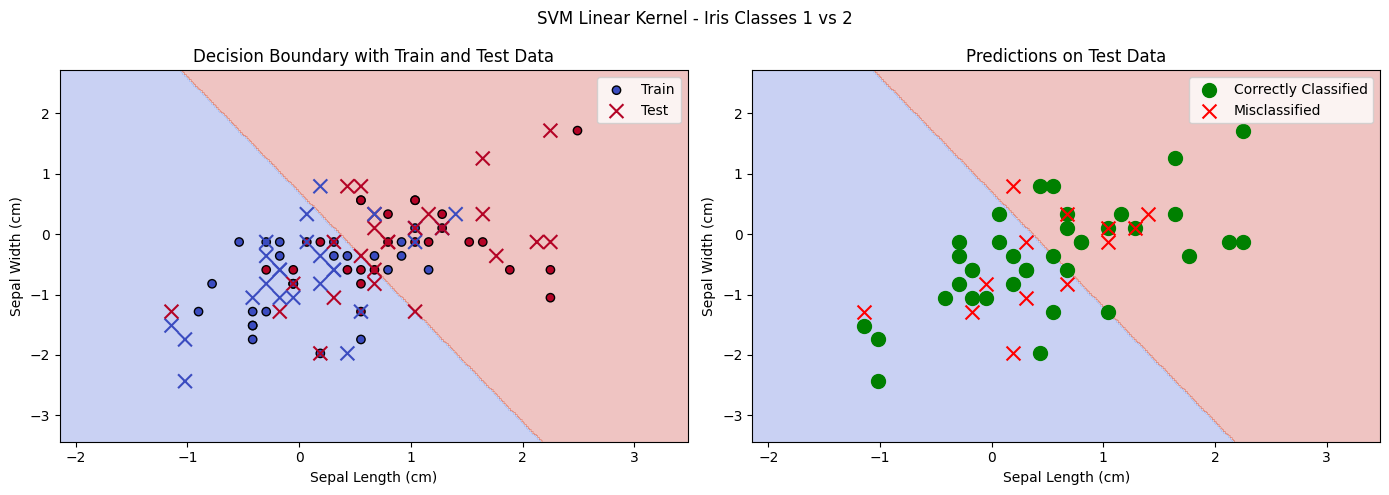

In [515]:
# Visualisation de la frontière de décision et des prédictions
def plot_decision_boundary_and_predictions(X_train, X_test, y_train, y_test, y_pred, model, title):
    h = 0.02  # Pas de la grille
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # Prédire sur la grille pour la frontière de décision
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Créer une figure avec deux sous-graphiques
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Graphique 1 : Frontière de décision avec données d'entraînement et de test
    ax1.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3)
    ax1.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', label='Train')
    ax1.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.coolwarm, marker='x', s=100, label='Test')
    ax1.set_xlabel('Sepal Length (cm)')
    ax1.set_ylabel('Sepal Width (cm)')
    ax1.set_title('Decision Boundary with Train and Test Data')
    ax1.legend()

    # Graphique 2 : Prédictions sur l'ensemble de test
    correct = y_test == y_pred
    incorrect = ~correct
    ax2.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3)
    ax2.scatter(X_test[correct, 0], X_test[correct, 1], c='green', marker='o', s=100, label='Correctly Classified')
    ax2.scatter(X_test[incorrect, 0], X_test[incorrect, 1], c='red', marker='x', s=100, label='Misclassified')
    ax2.set_xlabel('Sepal Length (cm)')
    ax2.set_ylabel('Sepal Width (cm)')
    ax2.set_title('Predictions on Test Data')
    ax2.legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Afficher la visualisation
plot_decision_boundary_and_predictions(X_train, X_test, y_train, y_test, y_pred, clf, 'SVM Linear Kernel - Iris Classes 1 vs 2')

## SVM Noyau Plynomiale

On va créer le meme model sauf cette fois avec un noyau polynomiale

### Créer et entrainer le modele SVM polynomial (degré 2)

In [516]:
# Créer et entrainer le modele SVM plolynomial (degré 3)
model_poly = SVC(C=0.7,kernel='poly',degree=2)
model_poly.fit(X_train,y_train)

SVC(C=0.7, degree=2, kernel='poly')

### Prédictions

In [517]:
# Prédictions
y_pred_poly = model_poly.predict(X_test)
y_pred_poly

array([2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 2, 1, 2,
       1, 1, 2, 1, 2, 2, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 1,
       1, 1, 2, 2, 2, 1])

### Evaluation

In [518]:
# Evaluation
print("Accuracy:",accuracy_score(y_test,y_pred_poly))
print("\nRapport de classification\n",classification_report(y_test,y_pred_poly))

Accuracy: 0.66

Rapport de classification
               precision    recall  f1-score   support

           1       0.62      0.84      0.71        25
           2       0.75      0.48      0.59        25

    accuracy                           0.66        50
   macro avg       0.68      0.66      0.65        50
weighted avg       0.68      0.66      0.65        50



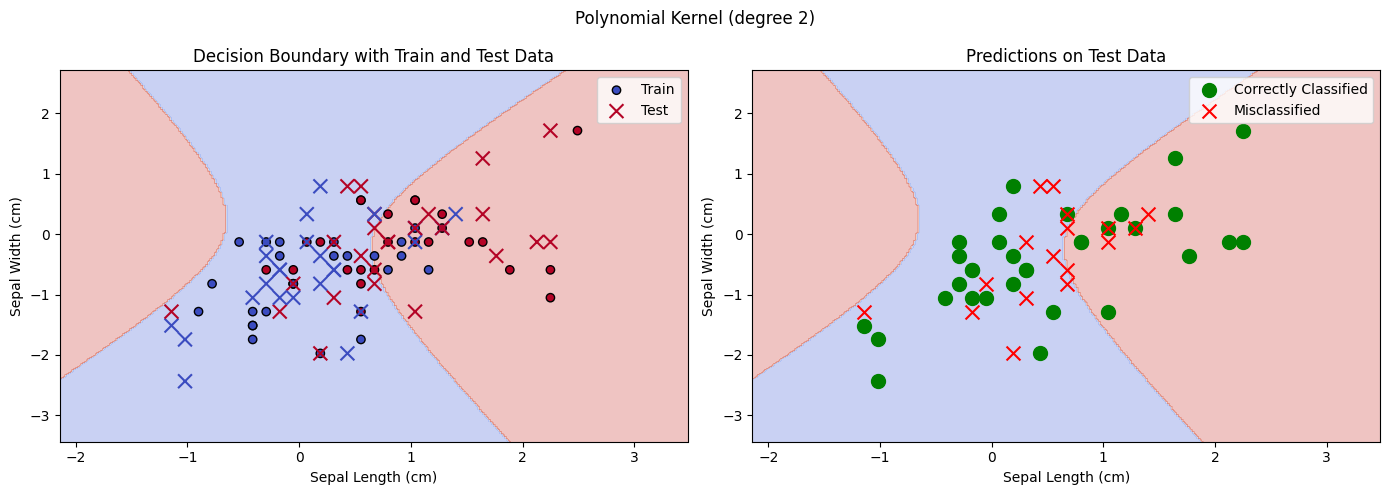

<Figure size 640x480 with 0 Axes>

In [519]:
plot_decision_boundary_and_predictions(X_train,X_test,y_train,y_test,y_pred_poly,model_poly,'Polynomial Kernel (degree 2)')
plt.suptitle('Comparison of SVM Kernels - Iris Classes 1 vs 2')
plt.tight_layout()
plt.show()

# 2 . SVM pour la classification des visages

In [520]:

import numpy as np

import matplotlib.pyplot as plt
from scipy.stats import loguniform

from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, classification_report , accuracy_score
from sklearn.model_selection import RandomizedSearchCV , train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

### Chargement des données

In [521]:
lfw_people = fetch_lfw_people(min_faces_per_person=70,resize=0.4)

n_samples, h, w = lfw_people.images.shape

X = lfw_people.data
n_features = X.shape[1]

y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("Total dataset size:")
print("n_samples : %d" % n_samples)
print("n_features :",n_features)
print("n_classes :",n_classes)

Total dataset size:
n_samples : 1288
n_features : 1850
n_classes : 7


### Choix de personnes

on va choisir deux personnes , par exemple Tony Blair et Colin Powell, pour accélerer le calcul

In [522]:
target_names

array(['Ariel Sharon', 'Colin Powell', 'Donald Rumsfeld', 'George W Bush',
       'Gerhard Schroeder', 'Hugo Chavez', 'Tony Blair'], dtype='<U17')

In [523]:
filter = np.isin(y,[np.where(target_names == 'Tony Blair')[0][0],
                  np.where(target_names == 'Colin Powell')[0][0]])
X , y = X[filter] , y[filter]

### Centrer et réduire les features

In [524]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Diviser les données

In [525]:
X_train , X_test , y_train , y_test = train_test_split(X_scaled,y,test_size = 0.25,random_state=42)

### Créer et entrainer le model

#### Influance du paramètre de régularisation C

pour evaluer l'influance de l'hyperparametre C on va afficher l'erreur de
prédiction en fonction de C sur une échelle logarithmique entre `1e5` et `1e-5`.

In [526]:
C_values = np.logspace(-5,5,num=11) # Echelle logartithmique de 1e-5 a 1e5

errors = []
for C in  C_values :
  model = SVC(C=C,kernel = 'linear',random_state=42)
  model.fit(X_train,y_train)
  y_pred = model.predict(X_test)
  error = 1 - accuracy_score(y_test , y_pred)
  errors.append(error)

**l'erreur en fonction de `C`**



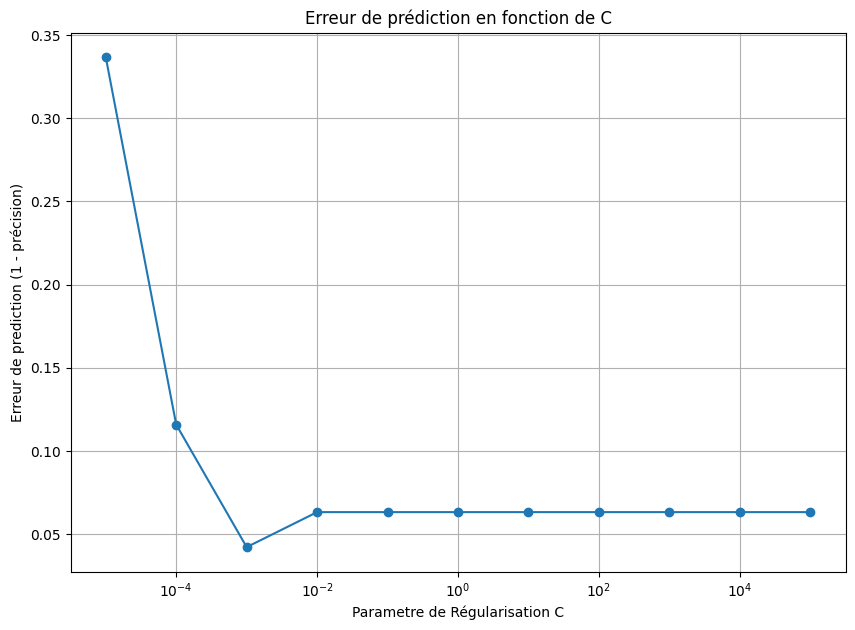

In [527]:
plt.figure(figsize=(10,7))
plt.semilogx(C_values,errors,marker='o')
plt.xlabel("Parametre de Régularisation C")
plt.ylabel("Erreur de prediction (1 - précision)")
plt.title("Erreur de prédiction en fonction de C")
plt.grid(True)
plt.show()

In [528]:
model = SVC(C=1e-3,kernel = 'linear',random_state=42)
model.fit(X_train,y_train)

SVC(C=0.001, kernel='linear', random_state=42)

In [529]:
y_pred = model.predict(X_test)

In [530]:
print(f"Accuracy : {accuracy_score(y_test,y_pred):.2f}")
print("Rapport de classification :\n",classification_report(y_test,y_pred))

Accuracy : 0.96
Rapport de classification :
               precision    recall  f1-score   support

           1       1.00      0.94      0.97        63
           6       0.89      1.00      0.94        32

    accuracy                           0.96        95
   macro avg       0.94      0.97      0.95        95
weighted avg       0.96      0.96      0.96        95



### Ajout de 300 variables de nuisance

In [531]:
np.random.seed(42)
n_noise = 300
noise = np.random.normal(0,1,(X_scaled.shape[0],n_noise)) # Bruit gaussien centré réduit
X_with_noise = np.hstack((X_scaled,noise))


In [532]:
X_train_noise , X_test_noise ,y_train_noise,y_test_noise = train_test_split(X_with_noise,y,test_size=0.25,random_state=42)

#### Entrainer et évaluer un SVM avec bruit

In [533]:
model_noise = SVC(C=1e-5 ,kernel='linear',random_state=42)
model_noise.fit(X_train_noise,y_train_noise)

SVC(C=1e-05, kernel='linear', random_state=42)

#### Prédictions

In [534]:
y_pred_noise = model_noise.predict(X_test_noise)

#### Evaluation du model

In [535]:
print(f'Accuracy:{accuracy_score(y_test_noise,y_pred_noise):.2f}')
print("\nClassification report\n",classification_report(y_test_noise,y_pred_noise))

Accuracy:0.66

Classification report
               precision    recall  f1-score   support

           1       0.66      1.00      0.80        63
           6       0.00      0.00      0.00        32

    accuracy                           0.66        95
   macro avg       0.33      0.50      0.40        95
weighted avg       0.44      0.66      0.53        95



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [536]:
error_noise = 1 - accuracy_score(y_test_noise,y_pred_noise)
print(f"Erreur avec 300 variables de nuisance : {error_noise:.2f}")

Erreur avec 300 variables de nuisance : 0.34


### Réduction de dimension avec PCA

In [537]:
n_components = 50 # Nombre de composantes principales
pca = PCA(n_components= n_components , random_state=42)
X_train_pca = pca.fit_transform(X_train_noise)
X_test_pca = pca.fit_transform(X_test_noise)

####  Entrainer et evaluer un SVM sur les données réduites

In [538]:
model_pca = SVC(C=1e-4,kernel ='linear',random_state=42)
model_pca.fit(X_train_pca,y_train)


SVC(C=0.0001, kernel='linear', random_state=42)

#### Prédictions



In [539]:
y_pred_pca = model_pca.predict(X_test_pca)

In [540]:
print(f"Accuracy : {accuracy_score(y_test_noise , y_pred_pca)}")
print("\nClassification report:\n",classification_report(y_test_noise,y_pred_pca))

Accuracy : 0.7578947368421053

Classification report:
               precision    recall  f1-score   support

           1       0.79      0.87      0.83        63
           6       0.68      0.53      0.60        32

    accuracy                           0.76        95
   macro avg       0.73      0.70      0.71        95
weighted avg       0.75      0.76      0.75        95



In [541]:
error_pca = 1 - accuracy_score(y_test, y_pred_pca)
print(f"Erreur après PCA (n_components={n_components}): {error_pca:.3f}")

Erreur après PCA (n_components=50): 0.242



Résumé des performances :
 - Sans bruit: 0.063
 - Avec 300 variables de nuisance: 0.337
 - Avec PCA après bruit: 0.242


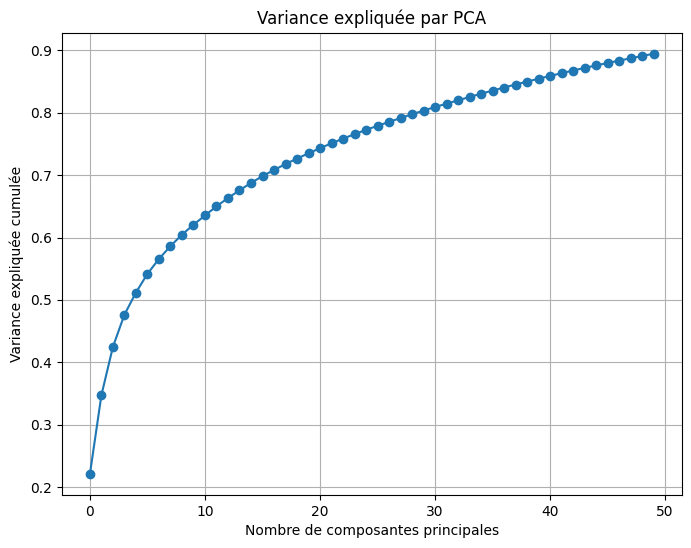

In [542]:
#Comparaison des performances
print("\nRésumé des performances :")
print(f" - Sans bruit: {error:.3f}")
print(f" - Avec {n_noise} variables de nuisance: {error_noise:.3f}")
print(f" - Avec PCA après bruit: {error_pca:.3f}")

# Visualisation de la variance expliquée par PCA
plt.figure(figsize=(8, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Nombre de composantes principales')
plt.ylabel('Variance expliquée cumulée')
plt.title('Variance expliquée par PCA')
plt.grid(True)
plt.show()

### L'effet du choix d'un noyau RBF

#### Creation et entrainement d'un SVM avec un noyau RBF

On essaie sur plusieurs valeur de C entre `1e-5` et `1e5`

In [543]:
C_values = np.logspace(-5,5,num=11) # Echelle logartithmique de 1e-5 a 1e5
#degree_values = np.arange(2,4)
errors = []
for C in  C_values :
  model = SVC(C=C,kernel = 'rbf',random_state=42)
  model.fit(X_train,y_train)
  y_pred = model.predict(X_test)
  error = 1 - accuracy_score(y_test , y_pred)
  errors.append(error)

#### Visualition de l'erreur de prédiction en fonction de C

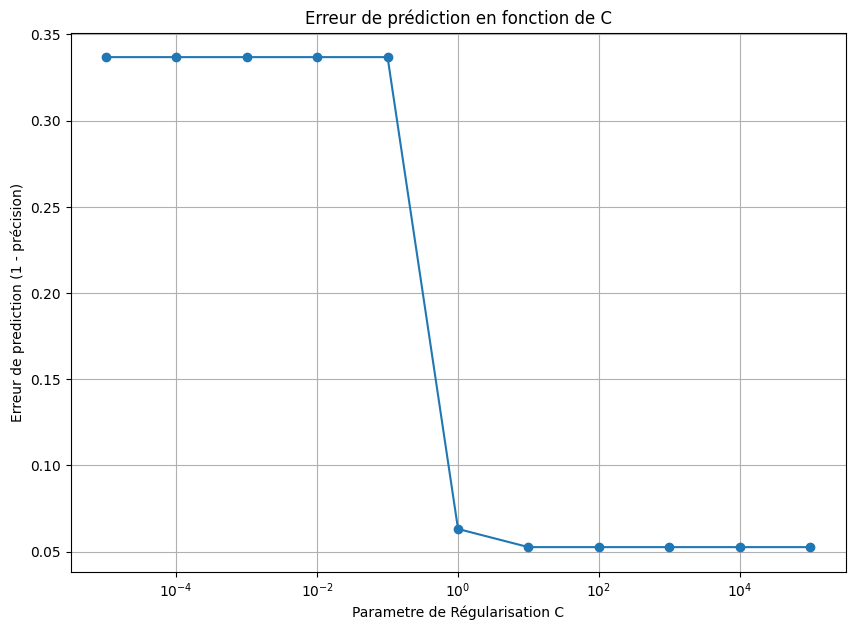

In [544]:
plt.figure(figsize=(10,7))
plt.semilogx(C_values,errors,marker='o')
plt.xlabel("Parametre de Régularisation C")
plt.ylabel("Erreur de prediction (1 - précision)")
plt.title("Erreur de prédiction en fonction de C")
plt.grid(True)
plt.show()

#### Choix du meilleure valeur de C (10)

In [545]:
model_rbf = SVC(C=10,kernel='rbf',random_state=42)
model_rbf.fit(X_train,y_train)

SVC(C=10, random_state=42)

In [546]:
y_pred = model_rbf.predict(X_test)

#### Rapport du classification

In [547]:
print(f"Accuracy :{accuracy_score(y_test,y_pred):.2f}")
print("\nClassification report:\n",classification_report(y_test,y_pred))

Accuracy :0.95

Classification report:
               precision    recall  f1-score   support

           1       0.95      0.97      0.96        63
           6       0.94      0.91      0.92        32

    accuracy                           0.95        95
   macro avg       0.94      0.94      0.94        95
weighted avg       0.95      0.95      0.95        95

